# 5. Modelo original: HGSB

**Hierarchical Geo-Shrinkage Gradient Boosting (HGSB):** *gradient boosting* programado desde cero en numpy en el
que, en cada iteración, las variables categóricas se reemplazan por la media del residuo de su categoría
**contraída hacia la de su categoría padre** en la jerarquía del dominio (región → país, región → elemento
productivo, tipo → subtipo de reserva).

## 5.1 Motivación

El EDA y los benchmarks dejaron cuatro hechos que motivan el diseño:

1. **La geografía domina el costo.** En SHAP, la región es el primer factor (2.2 USD/Bbl de efecto medio) y el
   tamaño del efecto de Kruskal-Wallis es grande para cuenca, país y región (ε² = 0.84, 0.75 y 0.59).
2. **La geografía es jerárquica y desbalanceada.** 45 de 99 países tienen un solo activo. El One-Hot con
   `min_frequency = 5` manda esos países a una categoría "infrecuente" común y pierde que pertenecen a regiones
   muy distintas.
3. **Las observaciones vienen agrupadas.** Un activo aporta hasta 10 filas casi iguales: contar filas sobrestima
   la evidencia de una categoría; lo correcto es contar activos.
4. **Combinar los benchmarks no ayudó** (capítulo 3.5): sus errores tienen correlación 0.96. La mejora tiene que
   venir de usar mejor la información, no de promediar modelos.

## 5.2 Formulación matemática

**Datos.** $\mathcal D = \{(\mathbf x_i, y_i, a_i)\}_{i=1}^n$, con $a_i \in \{1,\dots,A\}$ el activo de la fila $i$.
Cada $\mathbf x_i$ tiene variables numéricas $\mathbf u_i$ (año, log-producción, indicador de faltante) y
categóricas $c_i^{(1)},\dots,c_i^{(C)}$. Una función $\mathrm{pa}(\cdot)$ asigna a cada variable categórica su
variable padre (o ninguna).

**Boosting.** Con pérdida cuadrática $L(y,F)=\tfrac12 (y-F)^2$:

$$F_0 = \bar y, \qquad F_m(\mathbf x) = F_{m-1}(\mathbf x) + \eta\, h_m(\mathbf z_m(\mathbf x)), \qquad m = 1,\dots,M$$ (eq-boost)

donde el gradiente negativo es el residuo $r_i^{(m)} = y_i - F_{m-1}(\mathbf x_i)$.

**Residuo por activo.** $\bar r_a = \frac{1}{n_a}\sum_{i:\,a_i=a} r_i^{(m)}$.

**Codificación contraída.** Para la categoría $k$ de la variable $c$, con $S_k=\sum_{a\in k}\bar r_a$ y
$n_k = |\{a \in k\}|$ (número de **activos**):

$$\tilde e_k^{(m)} = \frac{S_k + \kappa\, \pi_k}{n_k + \kappa}, \qquad
\pi_k = \sum_{j} W_{kj}\, \tilde e_j^{(m),\,\mathrm{pa}(c)} \quad\text{(raíz: } \pi_k = \tfrac{1}{A}\textstyle\sum_a \bar r_a\text{)}$$ (eq-shrink)

$W_{kj}$ es la fracción de activos de la categoría $k$ que pertenecen a la categoría padre $j$. Solo depende de
la composición de los activos, no del objetivo. Una categoría **no vista** en entrenamiento hereda la codificación
de su padre.

**Árbol.** Sobre $\mathbf z_i = [\mathbf u_i, \tilde e^{(1)}(c_i^{(1)}),\dots,\tilde e^{(C)}(c_i^{(C)})]$ se
ajusta un árbol por histogramas con la ganancia de segundo orden ($g_i=-r_i$, $h_i=1$) y pesos de hoja
regularizados:

$$\mathrm{Gan} = \tfrac12\Big[\tfrac{G_L^2}{H_L+\lambda} + \tfrac{G_R^2}{H_R+\lambda} - \tfrac{(G_L+G_R)^2}{H_L+H_R+\lambda}\Big]-\gamma,
\qquad w_j^* = \frac{\sum_{i\in j} r_i}{H_j+\lambda}$$ (eq-gain)

### Sustento teórico

**Proposición 1 (contracción de Bayes empírico).** Si $\bar r_a \mid \theta_k \sim \mathcal N(\theta_k,\sigma^2)$
para los activos de la categoría $k$ y $\theta_k \sim \mathcal N(\pi_k, \tau^2)$, entonces
$\mathbb E[\theta_k \mid \bar r] = \frac{S_k + \kappa \pi_k}{n_k+\kappa}$ con $\kappa = \sigma^2/\tau^2$.

*Demostración.* La posterior de $\theta_k$ es normal con precisión $n_k/\sigma^2 + 1/\tau^2$ y media
$\big(\frac{S_k}{\sigma^2} + \frac{\pi_k}{\tau^2}\big)\big/\big(\frac{n_k}{\sigma^2}+\frac{1}{\tau^2}\big)$. Al multiplicar
numerador y denominador por $\sigma^2$ se obtiene la ecuación {eq}`eq-shrink`. Esta media posterior minimiza el
riesgo cuadrático bayesiano, y su versión empírica domina al promedio simple cuando hay tres o más categorías
(James-Stein; {cite}`james1961estimation,efron1975data`). $\square$

Consecuencias: si $n_k = 1$ (un solo activo), $\tilde e_k$ se acerca a la región tanto más cuanto mayor es
$\kappa$; si $n_k \to \infty$, $\tilde e_k \to S_k/n_k$. Con $\kappa = 0$ se recupera el promedio simple
(ablación "sin contracción").

**Proposición 2 (partición óptima por orden).** Para pérdida cuadrática y una variable categórica, la mejor
partición binaria de sus categorías separa las categorías **ordenadas por su media** en un punto de corte
{cite}`fisher1958grouping`. Por eso un umbral sobre $\tilde e$ explora particiones óptimas con un solo barrido de
$K$ puntos en vez de $2^{K-1}$. Con $\kappa > 0$ el orden es el de las medias contraídas, que es más estable en
categorías pequeñas.

**Proposición 3 (descenso monótono y terminación).** Con `subsample = 1`, $\eta \in (0,1]$ y $\lambda \ge 0$, la
pérdida de entrenamiento no aumenta en ninguna iteración.

*Demostración.* En una hoja con $H$ filas y suma de residuos $G$, el cambio de pérdida al sumar $\eta w^*$ es
$\sum (r_i-\eta w^*)^2-\sum r_i^2 = -\frac{\eta G^2}{H+\lambda}\big(2 - \frac{\eta H}{H+\lambda}\big) \le 0$, porque
$\eta H/(H+\lambda) \le 1$. Sumando sobre hojas, $L(F_m) \le L(F_{m-1})$. El algoritmo termina tras $M$ iteraciones
y la sucesión de pérdidas, acotada por debajo por 0, converge. La prueba unitaria
`test_training_loss_non_increasing` lo verifica numéricamente. $\square$

### Pseudocódigo

```text
Entrada: {(xᵢ, yᵢ, aᵢ)}, jerarquía pa(·), M, η, d, λ, γ, κ, B bins, subsample, colsample
Salida : F_M y, por iteración, las tablas ẽ y el árbol h_m
1  F₀ ← media(y)
2  para m = 1 … M:
3      rᵢ ← yᵢ − F_{m−1}(xᵢ)                         ▷ gradiente negativo
4      r̄ₐ ← media de rᵢ en el activo a              ▷ se cuenta por activo
5      para cada variable c en orden topológico (padres primero):
6          S_k ← Σ_{a∈k} r̄ₐ ;  n_k ← #activos en k
7          π_k ← W_k · ẽ_pa(c)   (raíz: media global de r̄)
8          ẽ_k ← (S_k + κ·π_k)/(n_k + κ)               ▷ ecuación (eq-shrink)
9      zᵢ ← [uᵢ, ẽ(cᵢ)] ; discretizar cada columna en ≤ B bins por cuantiles
10     muestrear filas (subsample) y columnas (colsample)
11     h_m ← árbol de profundidad ≤ d con la ganancia (eq-gain); detener un nodo si
         Gan ≤ 0 o H < 2·min_child_weight
12     F_m ← F_{m−1} + η·h_m(z)
13 Predicción de x nuevo: ẽ_c(x) desde las tablas (categoría no vista → ẽ del padre),
   F_M(x) = F₀ + η Σ_m h_m(z_m(x))
```

In [1]:
import sys, time, subprocess, warnings, pickle, json
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config as C
from src.data import load_model_data, split_dev_test
from src.original_model import HierarchicalShrinkageBoosting as HGSB, DEFAULT_HIERARCHY
from src.viz import set_style, SERIES

C.set_global_seed()
set_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
ORIG = C.RESULTS_DIR / "original"
dev, test = split_dev_test(load_model_data())
FEATS = C.SCENARIOS["A_estructural"]["numeric"] + C.SCENARIOS["A_estructural"]["categorical"]
print("Jerarquía:", DEFAULT_HIERARCHY)

Jerarquía: {'RegionName': None, 'CountryName': 'RegionName', 'ProductionElementName': 'RegionName', 'ReserveTypeName': None, 'SupplySubTypeName': 'ReserveTypeName', 'ReserveLocationName': None, 'MemberOpec': None}


## 5.3 Análisis de complejidad

Con $n$ filas, $A$ activos, $p$ variables de entrada al árbol, $K_c$ categorías de la variable $c$, $B$ bins y
profundidad $d$, cada iteración cuesta:

| Paso | Costo |
|---|---|
| Residuo y medias por activo | $O(n)$ |
| Codificación contraída (tablas y prior $W\tilde e$) | $O\big(\sum_c (A + K_c K_{\mathrm{pa}(c)})\big)$ |
| Discretización por cuantiles | $O(C\, n\log n)$ |
| Árbol por histogramas (una pasada de `bincount` por nivel + barrido de cortes) | $O(d\, n\, p + 2^d p B)$ |
| Actualización de $F$ | $O(n\, d)$ |

**Entrenamiento:** $O\big(M\,[\,n(C\log n + d\,p) + 2^d p B + \sum_c K_c K_{\mathrm{pa}(c)}\,]\big)$, casi lineal en
$n$. **Inferencia** de $m$ filas: $O(M\, m\,(C + d))$. **Memoria:** $O(M(2^d + \sum_c K_c))$ para los árboles y
las tablas. A continuación se contrasta con el tiempo medido al variar $n$ y $p$ (columnas numéricas de ruido),
con hiperparámetros fijos.

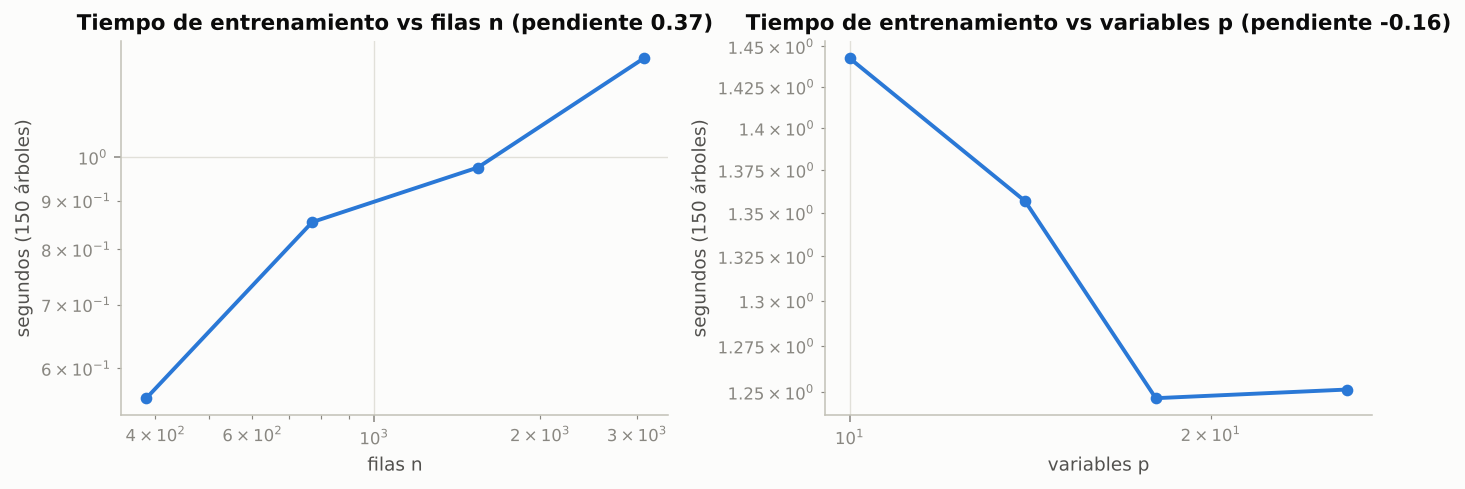

,variable,valor,s
0,n,385,0.5582
1,n,771,0.8545
2,n,1542,0.9751
3,n,3085,1.2693
4,p,10,1.4425
5,p,14,1.3568
6,p,18,1.2467
7,p,26,1.2514


In [2]:
Xd, yd = dev[FEATS + [C.GROUP]], dev[C.TARGET].to_numpy()
rng = np.random.default_rng(C.SEED)
rows = []
fixed = dict(n_estimators=150, learning_rate=0.05, max_depth=6, kappa=10, oof_folds=1, random_state=C.SEED)
for frac in [0.125, 0.25, 0.5, 1.0]:
    idx = rng.choice(len(Xd), int(frac * len(Xd)), replace=False)
    t = time.perf_counter(); HGSB(**fixed).fit(Xd.iloc[idx], yd[idx]); rows.append({"variable": "n", "valor": len(idx), "s": time.perf_counter() - t})
for k in [0, 4, 8, 16]:
    Xk = Xd.copy()
    noise = [f"ruido{j}" for j in range(k)]
    for c in noise:
        Xk[c] = rng.normal(size=len(Xk))
    t = time.perf_counter(); HGSB(numeric=["Year", "Production"] + noise, **fixed).fit(Xk, yd)
    rows.append({"variable": "p", "valor": 10 + k, "s": time.perf_counter() - t})
tim = pd.DataFrame(rows)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, v, lab in zip(axes, ["n", "p"], ["filas n", "variables p"]):
    s = tim[tim.variable == v]
    slope = np.polyfit(np.log(s.valor), np.log(s.s), 1)[0]
    ax.loglog(s.valor, s.s, "o-", color=SERIES[0])
    ax.set_title(f"Tiempo de entrenamiento vs {lab} (pendiente {slope:.2f})")
    ax.set_xlabel(lab); ax.set_ylabel("segundos (150 árboles)")
fig.tight_layout(); plt.show()
tim

La pendiente en log-log mide el exponente empírico. Frente a $n$ queda por debajo de 1: con pocos datos domina el
costo fijo por nodo ($2^d p B$), que no depende de $n$. Frente a $p$ es lineal o menor, como predice el término
$d\,n\,p$.

## 5.4 Implementación

La clase hereda de `BaseEstimator` y `RegressorMixin`, así que funciona con `Pipeline`, `cross_val_score`, `clone`
y la validación anidada del Entregable 2. Todo el núcleo usa solo numpy: tablas de codificación (`_tables`), árbol
por histogramas (`_grow_tree`, `_Tree.apply`) y boosting (`fit`, `staged_predict`).

```{literalinclude} ../src/original_model.py
:language: python
:lines: 1-40
```

El archivo completo, comentado y con *docstrings*, está en `src/original_model.py`. A continuación el núcleo de
la codificación:

```{literalinclude} ../src/original_model.py
:language: python
:pyobject: HierarchicalShrinkageBoosting._tables
```

## 5.5 Pruebas unitarias

`tests/test_original_model.py` verifica: (i) aprendizaje en datos sintéticos con solución conocida; (ii)
herencia del padre para una categoría no vista; (iii) los límites $\kappa=0$ (promedio) y $\kappa\to\infty$
(prior del padre); (iv) reproducibilidad con la misma semilla; (v) manejo de parámetros y entradas inválidas;
(vi) compatibilidad con `sklearn.base.clone` y la serialización con `joblib`; (vii) que el identificador del
activo no se usa para predecir; y (viii) la proposición 3 (pérdida monótona).

In [3]:
out = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider", "../tests/"],
                     capture_output=True, text=True)
print(out.stdout[-1500:])

...................                                                      [100%]
19 passed in 3.46s



## 5.6 Hiperparámetros

Se optimizaron con **optimización bayesiana** (Optuna-TPE, 8 ensayos iniciales, adquisición EI) dentro de la
**misma validación anidada** de los benchmarks: mismos 10 pliegues externos y 3 internos por activo, mismo
presupuesto de 30 evaluaciones y semilla 42 (`run_original.py`).

| Hiperparámetro | Rango | Escala |
|---|---|---|
| `n_estimators` | 100–800 | lineal |
| `learning_rate` | 0.01–0.3 | log |
| `max_depth` | 3–10 | lineal |
| `kappa` (κ) | 0.1–50 | log |
| `min_child_weight` | 1–20 | log |
| `reg_lambda` (λ) | 0.01–10 | log |
| `subsample`, `colsample` | 0.5–1 | lineal |

In [4]:
hp = []
for k in list(range(C.OUTER_FOLDS)) + ["final"]:
    r = pickle.load(open(C.RESULTS_DIR / "cache" / f"A_estructural__HGSB__Bayesiana__{k}.pkl", "rb"))
    hp.append({"pliegue": k, **r["best_params"], "RMSE interno": r["best_inner_rmse"], "RMSE externo": r["metrics"]["rmse"],
               "búsqueda (min)": r["search_time"] / 60})
hp = pd.DataFrame(hp)
hp

,pliegue,n_estimators,learning_rate,max_depth,kappa,min_child_weight,reg_lambda,subsample,colsample,RMSE interno,RMSE externo,búsqueda (min)
0,0,238,0.0788,5,20.3344,2.1655,0.7336,0.6006,0.7972,2.0803,1.6537,3.5157
1,1,673,0.0119,5,19.5820,1.9954,0.2440,0.6548,0.5371,2.1596,1.5118,4.3912
2,2,538,0.0111,6,36.1798,1.6502,0.0485,0.9429,0.6936,2.3288,1.3351,2.2336
3,3,350,0.0141,5,10.1068,1.4403,0.0141,0.7204,0.8723,2.4106,1.4344,1.6497
4,4,120,0.1105,3,41.1545,1.6592,0.7019,0.7734,0.7904,2.1840,3.3138,1.2163
5,5,681,0.0452,10,39.1828,16.2329,0.0230,0.5735,0.8485,2.3560,1.9799,3.9169
6,6,628,0.0123,9,9.5414,1.9328,2.5077,0.7714,0.5710,2.2616,1.7391,4.5379
7,7,649,0.0236,6,8.4150,1.5879,2.4360,0.6977,0.5684,2.0366,2.3761,2.8172
8,8,571,0.0296,4,14.8412,2.3815,0.0266,0.8217,0.6154,2.0746,2.0350,3.0702
9,9,141,0.0298,5,20.5024,1.1573,0.2799,0.7730,0.8966,2.0640,1.8958,1.6054


En casi todos los pliegues el optimizador eligió una **contracción fuerte** (κ alto): la información del padre
pesa como varios activos. Esto concuerda con la proposición 1, porque los efectos de país y cuenca están muy
dispersos alrededor de los de su región.

## 5.7 Estudio de ablación

Cada variante retira un componente y conserva los hiperparámetros de cada pliegue (10 pliegues externos):

In [5]:
abl = pd.read_csv(ORIG / "ablation.csv")
abl

,Variante,RMSE externo,Δ vs completo,Pliegues peores,p Wilcoxon
0,HGSB completo,1.927 ± 0.579,—,—,—
1,Sin jerarquía (contracción hacia la media global),2.002 ± 0.678,+0.075,5/10,0.375
2,Sin contracción (κ = 0),2.018 ± 0.595,+0.091,8/10,0.064
3,Codificación fuera de pliegue (K = 5),2.346 ± 0.538,+0.418,10/10,0.002
4,Sin codificación (One-Hot),2.110 ± 0.613,+0.182,7/10,0.049


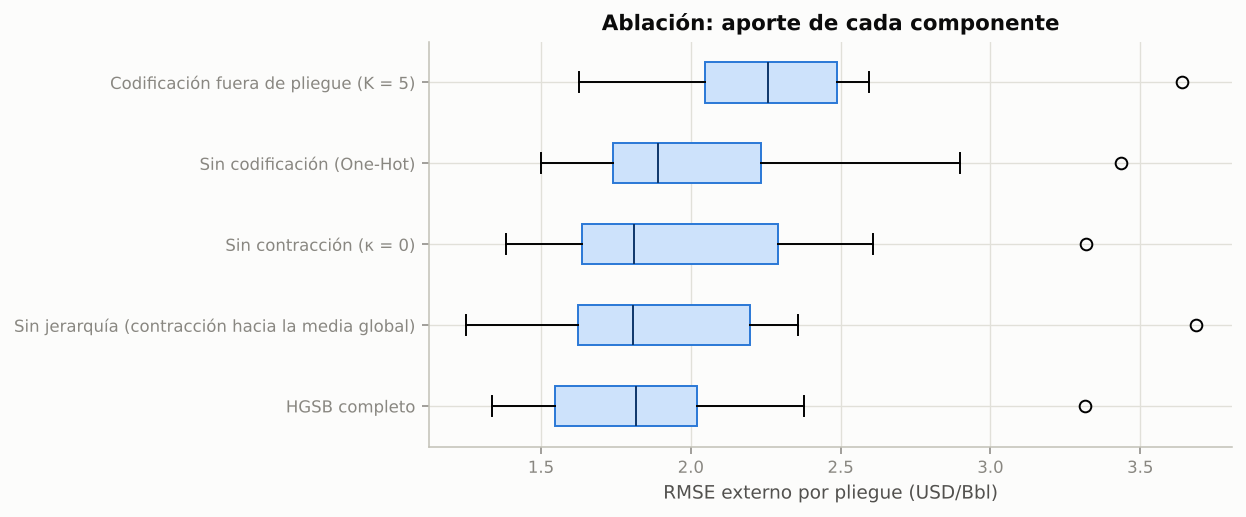

In [6]:
A = pd.read_csv(ORIG / "ablation_folds.csv", index_col=0)
fig, ax = plt.subplots(figsize=(9, 3.8))
order = A.mean().sort_values().index
ax.boxplot([A[c] for c in order], vert=False, tick_labels=order, patch_artist=True,
           boxprops=dict(facecolor="#cde2fb", color=SERIES[0]), medianprops=dict(color="#0d366b"))
ax.set_xlabel("RMSE externo por pliegue (USD/Bbl)"); ax.set_title("Ablación: aporte de cada componente")
fig.tight_layout(); plt.show()

## 5.8 Convergencia e interpretabilidad

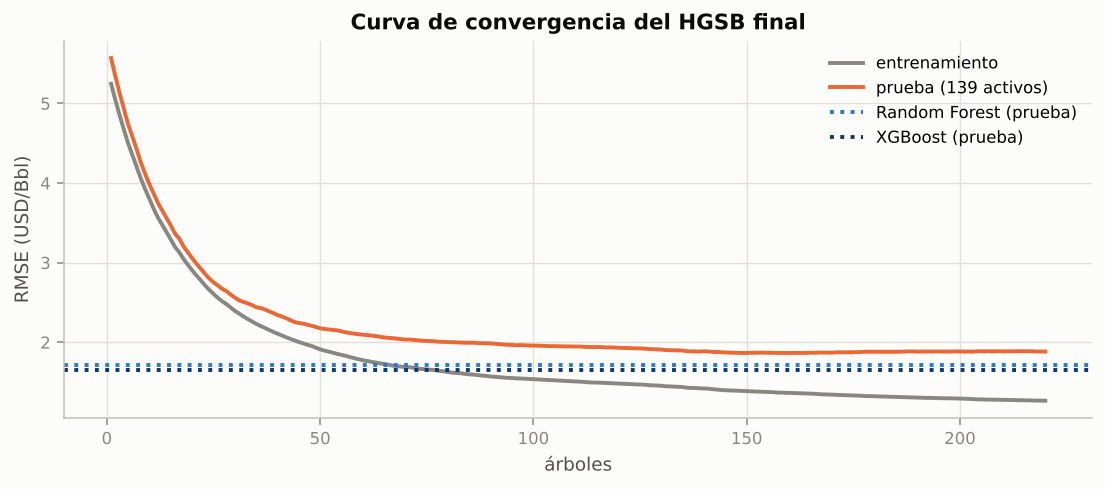

In [7]:
conv = pd.read_csv(ORIG / "convergence.csv")
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(conv.iteration, conv.train_rmse, label="entrenamiento", color="#898781")
ax.plot(conv.iteration, conv.test_rmse, label="prueba (139 activos)", color=SERIES[1])
ax.axhline(conv.rf_test_rmse.iloc[0], ls=":", color=SERIES[0], label="Random Forest (prueba)")
ax.axhline(conv.xgb_test_rmse.iloc[0], ls=":", color="#0d366b", label="XGBoost (prueba)")
ax.set_xlabel("árboles"); ax.set_ylabel("RMSE (USD/Bbl)"); ax.set_title("Curva de convergencia del HGSB final")
ax.legend(); fig.tight_layout(); plt.show()

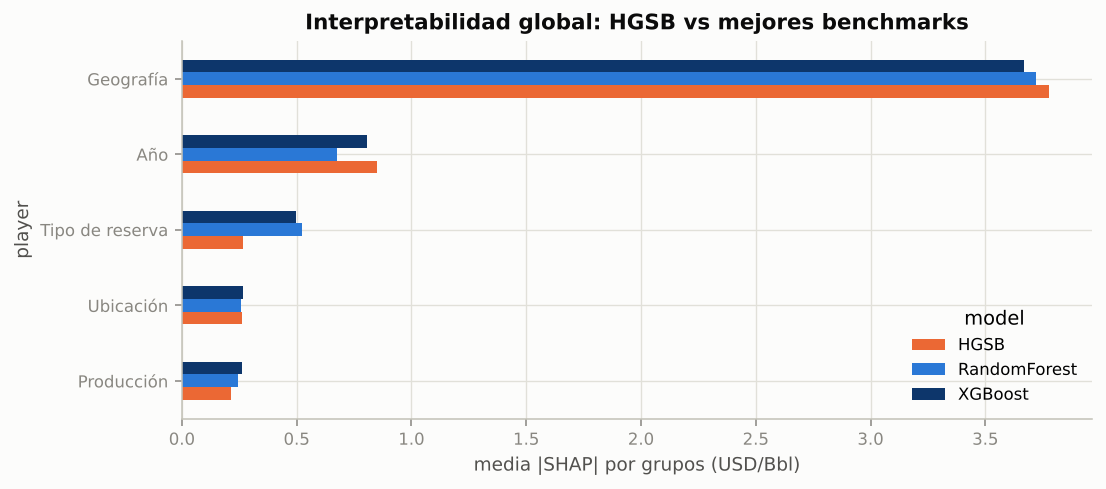

model,HGSB,RandomForest,XGBoost
player,,,
Producción,0.2154,0.2465,0.2633
Ubicación,0.2616,0.2571,0.2670
Tipo de reserva,0.2651,0.5248,0.4970
Año,0.8500,0.6771,0.8079
Geografía,3.7761,3.7202,3.6668


In [8]:
sg = pd.read_csv(C.RESULTS_DIR / "dashboard" / "shap_global.csv")
piv = sg.pivot(index="player", columns="model", values="mean_abs")[["HGSB", "RandomForest", "XGBoost"]].sort_values("HGSB")
ax = piv.plot.barh(figsize=(8, 3.6), color=[SERIES[1], SERIES[0], "#0d366b"])
ax.set_xlabel("media |SHAP| por grupos (USD/Bbl)"); ax.set_title("Interpretabilidad global: HGSB vs mejores benchmarks")
plt.tight_layout(); plt.show()
piv

Los tres modelos coinciden en el orden de importancia: geografía, luego año y tipo de reserva. El HGSB no cambia
**qué** explica el costo; cambia **cómo** usa la geografía, con información prestada entre niveles. La ventaja
frente a XGBoost viene de los países con pocos activos, donde el One-Hot no tiene suficiente información.

## 5.9 Alternativa explorada: bosques con pesos aprendidos por árbol

Antes de fijar el diseño del HGSB se probó otra familia de reglas de combinación: un Random Forest cuyos árboles
(entrenados con *bootstrap por activo*) reciben pesos distintos según su error fuera de bolsa, medido en activos
que no vieron (`run_weighted_forest.py`, mismos 10 pliegues externos e hiperparámetros de RF de cada pliegue):

- **A.** pesos uniformes $1/B$ (referencia);
- **B.** pesos globales $w_b \propto \exp(-\beta z_b)$, con $z_b$ el error OOB estandarizado del árbol;
- **C.** pesos locales por región, con el error del árbol en la región contraído hacia su error global:
  $e_{b,r} = (n_r\,\mathrm{MSE}_{b,r} + \kappa\,\mathrm{MSE}_b)/(n_r+\kappa)$;
- **D.** apilamiento convexo de los árboles con penalización ridge hacia los pesos uniformes.

$\beta$, $\kappa$ y la penalización se eligieron con el error OOB dentro del entrenamiento, nunca con el pliegue
externo.

In [9]:
wf = pd.read_csv(C.RESULTS_DIR / "weighted_forest" / "folds.csv")
cols = {"A_uniforme": "A. Uniforme (bootstrap por activo)", "B_global": "B. Pesos globales OOB",
        "C_local_region": "C. Pesos locales por región", "D_stacking": "D. Apilamiento convexo",
        "RF_sklearn": "Random Forest (scikit-learn)", "HGSB": "HGSB"}
pd.DataFrame({"RMSE externo medio": wf[list(cols)].mean().values,
              "d.e. entre pliegues": wf[list(cols)].std(ddof=1).values}, index=list(cols.values())).sort_values("RMSE externo medio")

,RMSE externo medio,d.e. entre pliegues
HGSB,1.9275,0.5789
Random Forest (scikit-learn),2.0082,0.5486
B. Pesos globales OOB,2.0085,0.5083
C. Pesos locales por región,2.0175,0.5343
D. Apilamiento convexo,2.0411,0.5395
A. Uniforme (bootstrap por activo),2.0440,0.5103


Reponderar los árboles da como mucho un 2 % frente a los pesos uniformes y, en el mejor caso, empata con el Random
Forest de scikit-learn; ninguna variante se acerca al HGSB. Con árboles profundos que cometen errores muy parecidos,
cambiar sus pesos casi no mueve el promedio, y estimar pesos por región con pocos activos agrega ruido (al ampliar
la rejilla de búsqueda la variante C empeoró). La conclusión refuerza el diseño del HGSB: la mejora no viene de
**cómo se combinan** los árboles, sino de **qué ven**, es decir, de una codificación de la geografía que comparte
información entre niveles.